# <b>2. Preparing the GenLLM </b>
This notebook focuses on experimenting with and evaluating the Large Language Model used in Tia — Conversational AI Portfolio.

The model used in this project was trained/fine-tuned using Google Colab. 

In [1]:
!pip install -q \
    trl==0.11.1 \
    transformers==4.45.2 \
    datasets==3.0.1 \
    peft==0.13.2 \
    accelerate==1.0.1 \
    evaluate==0.4.3 \
    scikit-learn \
    pandas \
    numpy \
    torchmetrics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.4/44.4 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 318.4/318.4 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 97.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 471.6/471.6 kB 41.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 320.7/320.7 kB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 330.9/330.9 kB 30.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 63.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.6/177.6 kB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 44.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 109.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━

### Importing Libraries

In [2]:
import torch
from torch.utils.data import Dataset
from tqdm import tqdm
import evaluate
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig, TaskType, get_peft_model
from trl import SFTConfig, SFTTrainer, DataCollatorForCompletionOnlyLM

import matplotlib.pyplot as plt

In [3]:
device = 'cuda'

## 1. Dataset Preparation

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
dataset_path = '/content/drive/MyDrive/Tia/Datasets/tia_genllm_sft_5000.jsonl'

In [6]:
dataset = load_dataset('json', data_files = dataset_path)
print(dataset)

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['messages'],
        num_rows: 5000
    })
})


In [7]:
dataset = dataset.shuffle(seed = 42)

In [8]:
dataset['train'][2]

{'messages': [{'role': 'system',
   'content': "You are Tia, Tanmay's professional AI Assistant. You speak on behalf of Tanmay here."},
  {'role': 'user',
   'content': "User Query:\nWhat's the temperature outside\n\nRetrieved Guidance:\nHands-on work with Docker, Postman, GitHub Actions, and VS Code."},
  {'role': 'assistant',
   'content': "I'm here to share information about Tanmay's career and projects. Is there something about his work or experience you'd like to know?"}]}

### Train-Test Split

In [9]:
dataset_split = dataset['train'].train_test_split(test_size = 0.05, seed = 42)
train_dataset = dataset_split['train']
test_dataset = dataset_split['test']

dataset_split

DatasetDict({
    train: Dataset({
        features: ['messages'],
        num_rows: 4750
    })
    test: Dataset({
        features: ['messages'],
        num_rows: 250
    })
})

### Tokenizer

In [11]:
tokenizer = AutoTokenizer.from_pretrained(model_name)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [12]:
def format_chat(example):
    return {
        "text": tokenizer.apply_chat_template(
            example['messages'],
            tokenize = False,
            add_generation_prompt = False
        )
    }

train_dataset = train_dataset.map(format_chat)
test_dataset = test_dataset.map(format_chat)

Map:   0%|          | 0/4750 [00:00<?, ? examples/s]

Map:   0%|          | 0/250 [00:00<?, ? examples/s]

## 2. Model

In [10]:
model_name = "Qwen/Qwen2.5-3B-Instruct"

In [13]:
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype = torch.float16
)

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.97G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

## 3. Perform Fine-Tuning with LoRA

In [14]:
lora_config = LoraConfig(
    task_type = TaskType.CAUSAL_LM,
    r = 16,
    lora_alpha = 32,
    lora_dropout = 0.05,
    target_modules = [
        'q_proj',
        'k_proj',
        'v_proj',
        'o_proj',
        'gate_proj',
        'up_proj',
        'down_proj'
    ],
    bias = 'none'
)

### Wrapping Model with LoRA

In [15]:
model = get_peft_model(model, lora_config)

In [16]:
model.print_trainable_parameters()

trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607


### SFT Config

In [17]:
from trl import SFTConfig

sft_config = SFTConfig(
    output_dir = '/content/drive/MyDrive/Tia/Saved Models/',

    num_train_epochs = 2,

    per_device_train_batch_size = 1,
    per_device_eval_batch_size = 1,

    gradient_accumulation_steps = 8,

    learning_rate = 2e-4,

    fp16 = True,
    bf16 = False,

    logging_steps = 10,
    eval_steps = 100,
    save_steps = 100,

    evaluation_strategy = 'steps',
    save_strategy = 'steps',

    max_seq_length = 512,

    report_to = "none",

    seed = 42
)

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1545: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


### SFT Trainer

In [18]:
trainer = SFTTrainer(
    model = model,
    train_dataset = train_dataset,
    eval_dataset = test_dataset,
    tokenizer = tokenizer,
    dataset_text_field = 'text',
    args = sft_config
)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_deprecation.py:100: FutureWarning: Deprecated argument(s) used in '__init__': dataset_text_field. Will not be supported from version '1.0.0'.

Deprecated positional argument(s) used in SFTTrainer, please use the SFTConfig to set these arguments instead.
  warnings.warn(message, FutureWarning)
/usr/local/lib/python3.13/dist-packages/trl/trainer/sft_trainer.py:321: UserWarning: You passed a `dataset_text_field` argument to the SFTTrainer, the value you passed will override the one in the `SFTConfig`.
  warnings.warn(


Map:   0%|          | 0/4750 [00:00<?, ? examples/s]

Map:   0%|          | 0/250 [00:00<?, ? examples/s]

In [19]:
trainer.train()

Step,Training Loss,Validation Loss
100,0.456300,0.452517
200,0.326000,0.334412
300,0.285800,0.282393
400,0.266400,0.256788
500,0.229900,0.239153
600,0.216000,0.237082
700,0.209600,0.231433
800,0.219600,0.223631
900,0.203200,0.219362
1000,0.203800,0.215580


TrainOutput(global_step=1186, training_loss=0.2927502298234486, metrics={'train_runtime': 3627.4834, 'train_samples_per_second': 2.619, 'train_steps_per_second': 0.327, 'total_flos': 1.5795646089879552e+16, 'train_loss': 0.2927502298234486, 'epoch': 1.9974736842105263})

In [20]:
trainer.save_model(
    "/content/drive/MyDrive/Tia/Saved Models/Tia_v1"
)

tokenizer.save_pretrained(
    "/content/drive/MyDrive/Tia/Saved Models/Tia_v1"
)

('/content/drive/MyDrive/Tia/Saved Models/Tia_v1/tokenizer_config.json',
 '/content/drive/MyDrive/Tia/Saved Models/Tia_v1/special_tokens_map.json',
 '/content/drive/MyDrive/Tia/Saved Models/Tia_v1/vocab.json',
 '/content/drive/MyDrive/Tia/Saved Models/Tia_v1/merges.txt',
 '/content/drive/MyDrive/Tia/Saved Models/Tia_v1/added_tokens.json',
 '/content/drive/MyDrive/Tia/Saved Models/Tia_v1/tokenizer.json')

In [21]:
log_history_lora = trainer.state.log_history

In [22]:
print(log_history_lora)

[{'loss': 2.174, 'grad_norm': 1.002605676651001, 'learning_rate': 0.00019831365935919058, 'epoch': 0.016842105263157894, 'step': 10}, {'loss': 1.0587, 'grad_norm': 0.7701324820518494, 'learning_rate': 0.00019662731871838111, 'epoch': 0.03368421052631579, 'step': 20}, {'loss': 0.8584, 'grad_norm': 0.8448036313056946, 'learning_rate': 0.00019494097807757168, 'epoch': 0.05052631578947368, 'step': 30}, {'loss': 0.7848, 'grad_norm': inf, 'learning_rate': 0.00019342327150084318, 'epoch': 0.06736842105263158, 'step': 40}, {'loss': 0.6752, 'grad_norm': 0.8412848711013794, 'learning_rate': 0.00019173693086003372, 'epoch': 0.08421052631578947, 'step': 50}, {'loss': 0.6141, 'grad_norm': 1.1076629161834717, 'learning_rate': 0.00019005059021922428, 'epoch': 0.10105263157894737, 'step': 60}, {'loss': 0.5562, 'grad_norm': 1.1478400230407715, 'learning_rate': 0.00018836424957841485, 'epoch': 0.11789473684210526, 'step': 70}, {'loss': 0.5175, 'grad_norm': 1.116119384765625, 'learning_rate': 0.000186677

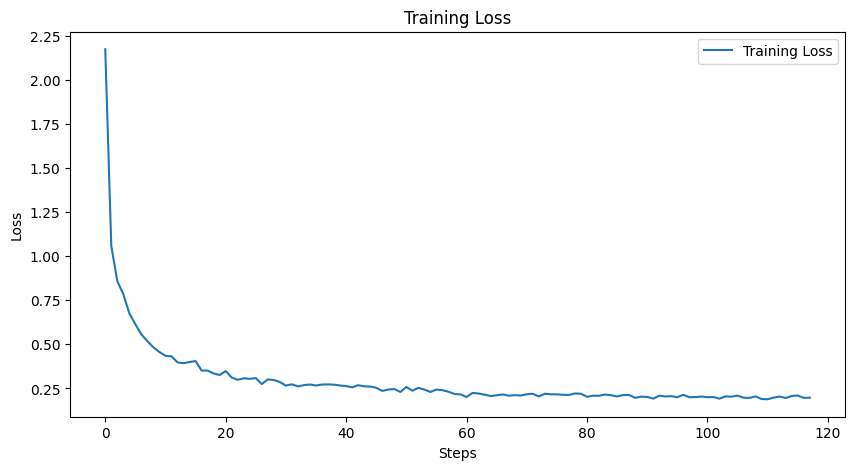

In [23]:
train_loss = [log['loss'] for log in log_history_lora if 'loss' in log]

plt.figure(figsize = (10, 5))
plt.plot(train_loss, label = 'Training Loss')

plt.xlabel('Steps')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.legend()
plt.show()

---

# <b>Inference Section

In [1]:
import torch
import os

from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import PeftModel

In [4]:
device = 'mps'

In [2]:
BASE_MODEL = 'Qwen/Qwen2.5-3B-Instruct'
LORA_PATH = '../models/Tia_v1'

In [3]:
tokenizer = AutoTokenizer.from_pretrained(LORA_PATH)

In [5]:
base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    torch_dtype = torch.float16
).to(device)

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

In [6]:
model = PeftModel.from_pretrained(
    base_model,
    LORA_PATH
)

In [7]:
from transformers import TextIteratorStreamer
from threading import Thread

In [14]:
def generate_response(user_prompt, max_new_tokens=300):

    model.eval()

    messages = [
        {
            "role": "system",
            "content": (
                "You are Tia, Tanmay's professional AI Assistant. "
                "You speak on behalf of Tanmay here. "

                "Use the Retrieved Guidance provided in the user prompt "
                "to answer the user's question. "

                "Do not invent or assume information that is not present "
                "in the Retrieved Guidance. "

                "If the Retrieved Guidance does not contain enough information "
                "to answer the question, say that you do not have enough "
                "information rather than guessing. "

                "Only answer questions related to Tanmay's professional "
                "background, projects, skills, education, and experience. "

                "If the question is unrelated to Tanmay, politely redirect "
                "the user toward his professional work. "

                "Keep responses professional, friendly, conversational, "
                "and concise. "

                "Naturally encourage the user to continue the conversation "
                "when appropriate."
            )
        },
        {
            "role": "user",
            "content": user_prompt
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    streamer = TextIteratorStreamer(
        tokenizer,
        skip_prompt=True,
        skip_special_tokens=True
    )

    generation_kwargs = {
        **inputs,
        "streamer": streamer,
        "max_new_tokens": max_new_tokens,
        "do_sample": False,
        "pad_token_id": tokenizer.pad_token_id,
        "eos_token_id": tokenizer.eos_token_id
    }

    thread = Thread(
        target=model.generate,
        kwargs=generation_kwargs
    )

    thread.start()

    response = ""

    for new_text in streamer:
        print(new_text, end="", flush=True)
        response += new_text

    thread.join()

In [24]:
user_prompt = """

User Query: Tell me about Tanmay's AI experience.

Retrieved Guidance:

Tanmay has practical experience in AI, Generative AI, Machine Learning,
LLMs, NLP, and Retrieval-Augmented Generation.

He has worked with transformer models, embeddings, vector databases,
retrieval systems, classifiers, and parameter-efficient fine-tuning
using PEFT and LoRA.

His major AI projects include KAARSHIKA, an agricultural AI system,
and MIRA, a mine intelligence and risk assessment system.

He has also built Tia, a conversational AI portfolio using RAG,
embeddings, ChromaDB, and an LLM.

He has worked with technologies including Python, PyTorch,
Hugging Face Transformers, DistilBERT, Qwen2.5-3B-Instruct,
DPR, FAISS, ChromaDB, PEFT, LoRA, LangChain, and Gradio.
"""

generate_response(user_prompt)

On the AI side, he has worked with transformer models, embeddings, vector databases, retrieval systems, classifiers, and parameter-efficient fine-tuning techniques like PEFT and LoRA. He has also built projects such as KAARSHIKA, an agricultural AI system, and MIRA, a mine intelligence and risk assessment system. Would you like more detail on any of that?